# Notebook 11d: LightGBM generation carport
---
- LightGBM-model dat de opwek (`generation`) van de **carport** 3 dagen vooruit voorspelt, op 5-minutenresolutie.
- Opzet is gelijk aan het GRU-notebook (zelfde data-filter, 60/25/15 chronologische split, 7 dagen historie, 3 dagen horizon, testvensters met stride 12), zodat de MAE direct vergelijkbaar is.
- Code volgt notebook 11b (LightGBM generation huis); alleen het locatie-filter (`carport`) en de bestandsnamen verschillen, zodat huis en carport direct vergelijkbaar zijn.
- Runtime van het model (features bouwen, trainen, voorspellen) wordt bijgehouden met `time`.

### Inladen
---
1. Libraries en paths inladen

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import lightgbm as lgb

start_notebook = time.perf_counter()
runtimes = {}                                   # hierin komen alle gemeten tijden (seconden)

# Werkt zowel vanuit models/ als vanuit een submap van models/
KANDIDATEN = [Path("../prepared_data/forecast_targets_with_weather.parquet"),
              Path("../../prepared_data/forecast_targets_with_weather.parquet")]
DATA_DIR = next(p for p in KANDIDATEN if p.exists())
print("Data:", DATA_DIR.resolve())
print("LightGBM versie:", lgb.__version__)

Data: C:\Users\casde\Desktop\Project3\Project3_Deel1\prepared_data\forecast_targets_with_weather.parquet
LightGBM versie: 4.7.0


In [2]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "prepared_data").exists())
split = pd.read_parquet(ROOT / "prepared_data" / "model_split.parquet").iloc[0]

2. Data inladen en filteren (zelfde filter als het GRU-notebook)
---

In [3]:
t0 = time.perf_counter()
df = pd.read_parquet(DATA_DIR)
carport_generation = df[(df["location"] == "carport") & (df["target_type"] == "generation")].copy()
carport_generation = carport_generation.dropna(subset=["pow_imputed", "Windrichting", "WindSnelheid", "LuchtVochtigheid"])
carport_generation = carport_generation.sort_values("timestamp").reset_index(drop=True)
runtimes["data inladen"] = time.perf_counter() - t0

print(carport_generation.shape)
print("Periode:", carport_generation["timestamp"].min(), "t/m", carport_generation["timestamp"].max())

(211657, 16)
Periode: 2024-03-08 01:05:00+01:00 t/m 2026-09-02 08:10:00+02:00


In [4]:
carport_generation = carport_generation[(carport_generation["timestamp"] >= split["train_start"]) & (carport_generation["timestamp"] < split["test_end"])].reset_index(drop=True)

### Voorspel instellingen
---
- LightGBM is geen sequentiemodel. Daarom wordt de forecast als tabel opgebouwd: elke rij is één combinatie van **forecastmoment** (origin) en **stap vooruit** (1 t/m 864).
- De horizon-stap is zelf een feature, zodat één model alle 864 stappen voorspelt.

In [5]:
stap_per_dag = 24 * 12                     # 288 stappen per dag (5 minuten)

aantal_dagen_input = 7                     # zelfde als GRU: historie die beschikbaar moet zijn
input_len = aantal_dagen_input * stap_per_dag

aantal_dagen_forecast = 3                  # horizon
horizon = aantal_dagen_forecast * stap_per_dag

stride_test = 12                           # zelfde testvensters als GRU (elk uur een nieuwe forecast)
stride_train = 72                          # trainvensters elke 6 uur (lager = meer data, meer geheugen/tijd)
stride_val = 144                           # validatievensters elke 12 uur (voor early stopping)

TRAIN_FRAC = 0.60
VAL_FRAC = 0.25

TARGET_COL = "pow_imputed"

# Weer op het voorspelde tijdstip gebruiken? True = aanname dat er een (perfecte) weersverwachting is.
# False = alleen weer tot aan het forecastmoment (eerlijker vergelijk met het GRU-model).
GEBRUIK_TOEKOMST_WEER = True

### Features
---
1. Features per tijdstip (kalender + weer)

In [6]:
tijd = pd.to_datetime(carport_generation["timestamp"])
minuut_van_dag = tijd.dt.hour * 60 + tijd.dt.minute
dag_van_week = tijd.dt.dayofweek + tijd.dt.hour / 24
dag_van_jaar = tijd.dt.dayofyear

tijd_features = pd.DataFrame({
    "uur_sin":  np.sin(2 * np.pi * minuut_van_dag / 1440),
    "uur_cos":  np.cos(2 * np.pi * minuut_van_dag / 1440),
    "week_sin": np.sin(2 * np.pi * dag_van_week / 7),
    "week_cos": np.cos(2 * np.pi * dag_van_week / 7),
    "jaar_sin": np.sin(2 * np.pi * dag_van_jaar / 365.25),
    "jaar_cos": np.cos(2 * np.pi * dag_van_jaar / 365.25),
})

rad = np.deg2rad(carport_generation["Windrichting"])
weer_features = pd.DataFrame({
    "Temperatuur":      carport_generation["Temperatuur"],
    "GlobaleStraling":  carport_generation["GlobaleStraling"],
    "DuurNeerslag":     carport_generation["DuurNeerslag"],
    "SomNeerslag":      carport_generation["SomNeerslag"],
    "WindSnelheid":     carport_generation["WindSnelheid"],
    "LuchtVochtigheid": carport_generation["LuchtVochtigheid"],
    "wind_sin":         np.sin(rad),
    "wind_cos":         np.cos(rad),
})

TIJD_COLS = list(tijd_features.columns)
WEER_COLS = list(weer_features.columns)
tijd_arr = tijd_features.to_numpy(np.float32)
weer_arr = weer_features.to_numpy(np.float32)
y_arr = carport_generation[TARGET_COL].to_numpy(np.float64)
cumsum = np.concatenate([[0.0], np.cumsum(y_arr)])     # voor snelle rolling gemiddelden
straling_24u_arr = (pd.Series(weer_features["GlobaleStraling"].to_numpy(np.float64))
                    .rolling(stap_per_dag, min_periods=1).mean().to_numpy(np.float32))

n = len(y_arr)
tijd = pd.to_datetime(carport_generation["timestamp"])
i_train = tijd.searchsorted(split["train_end"])
i_val = tijd.searchsorted(split["test_start"])
print(f"n = {n} | train t/m {i_train} | val t/m {i_val} | test t/m {n}")

n = 48228 | train t/m 33240 | val t/m 40740 | test t/m 48228


C:\Users\casde\AppData\Local\Temp\ipykernel_21744\398764455.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  dag_van_week = tijd.dt.dayofweek + tijd.dt.hour / 24
C:\Users\casde\AppData\Local\Temp\ipykernel_21744\398764455.py:4: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  dag_van_jaar = tijd.dt.dayofyear


2. Rijen bouwen per forecastmoment
---
Voor forecastmoment `o` (eerste voorspelde index) en stap `h` is het doel `y[o + h]`. Er wordt alleen data van vóór `o` gebruikt:
- `laatste`, `gem_1u`, `gem_24u`, `gem_7d`: niveau van de opwek vlak voor het forecastmoment
- `zelfde_tijd_recent`: opwek op hetzelfde tijdstip van de dag, de meest recente dag die al bekend is
- `zelfde_tijd_gem7`: gemiddelde daarvan over 7 dagen
- `straling_24u`: gemiddelde straling over de laatste 24 uur
- `stap`, `dag_vooruit`: hoe ver vooruit
- kalender (en eventueel weer) op het voorspelde tijdstip

In [7]:
def gem_venster(eind, lengte):
    """Gemiddelde van y[eind-lengte : eind] voor een array met eindindices."""
    return (cumsum[eind] - cumsum[eind - lengte]) / lengte


def bouw_rijen(origins):
    origins = np.asarray(origins)
    h = np.tile(np.arange(horizon), len(origins))
    o = np.repeat(origins, horizon)
    t = o + h                                        # index van het voorspelde tijdstip
    k = h // stap_per_dag + 1                        # aantal dagen terug zodat het tijdstip al bekend is

    X = {
        "stap": h.astype(np.float32),
        "dag_vooruit": (k - 1).astype(np.float32),
        "laatste": y_arr[o - 1],
        "gem_1u": gem_venster(o, 12),
        "gem_24u": gem_venster(o, stap_per_dag),
        "gem_7d": gem_venster(o, input_len),
        "zelfde_tijd_recent": y_arr[t - stap_per_dag * k],
        "zelfde_tijd_gem7": np.mean([y_arr[t - stap_per_dag * (k + j)] for j in range(7)], axis=0),
        "straling_24u": straling_24u_arr[o - 1],
    }
    X = pd.DataFrame(X).astype(np.float32)
    X[TIJD_COLS] = tijd_arr[t]
    if GEBRUIK_TOEKOMST_WEER:
        X[WEER_COLS] = weer_arr[t]                   # weer op het voorspelde tijdstip
    else:
        X[WEER_COLS] = weer_arr[o - 1]               # laatst bekende weer
    return X, y_arr[t]


MIN_HIST = stap_per_dag * (aantal_dagen_forecast + 7)   # genoeg historie voor zelfde_tijd_gem7

# train: doel moet volledig in train vallen
train_origins = np.arange(max(MIN_HIST, input_len), i_train - horizon + 1, stride_train)
# val: doel volledig in val (historie mag uit train komen)
val_origins = np.arange(i_train, i_val - horizon + 1, stride_val)
# test: exact dezelfde vensters als de GRU (7 dagen historie binnen de testset, stride 12)
test_origins = i_val + input_len + np.arange(0, (n - i_val) - input_len - horizon + 1, stride_test)

t0 = time.perf_counter()
X_train, y_train = bouw_rijen(train_origins)
X_val, y_val = bouw_rijen(val_origins)
runtimes["features bouwen"] = time.perf_counter() - t0

FEATURES = list(X_train.columns)
print(f"forecastmomenten | train: {len(train_origins)} | val: {len(val_origins)} | test: {len(test_origins)}")
print(f"rijen            | train: {len(X_train):,} | val: {len(X_val):,}")
print(f"aantal features: {len(FEATURES)}")
print(f"Features bouwen: {runtimes['features bouwen']:.1f}s")

forecastmomenten | train: 410 | val: 47 | test: 385
rijen            | train: 354,240 | val: 40,608
aantal features: 23
Features bouwen: 0.1s


### Model
---
- Objective `l1` (MAE), net als de L1-loss van de GRU.
- Early stopping op de validatieset.

In [8]:
params = {
    "objective": "l1",
    "metric": "l1",
    "learning_rate": 0.05,
    "num_leaves": 63,
    "min_data_in_leaf": 200,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "lambda_l2": 1.0,
    "verbosity": -1,
    "seed": 42,
}
n_rondes = 3000

dtrain = lgb.Dataset(X_train, label=y_train, free_raw_data=False)
dval = lgb.Dataset(X_val, label=y_val, reference=dtrain, free_raw_data=False)

evals = {}
start_totaal = time.perf_counter()                  # start tijd
model = lgb.train(
    params,
    dtrain,
    num_boost_round=n_rondes,
    valid_sets=[dtrain, dval],
    valid_names=["train", "val"],
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(100), lgb.record_evaluation(evals)],
)
runtimes["training"] = time.perf_counter() - start_totaal

print(f"\nTotale trainingstijd: {runtimes['training']:.1f}s ({runtimes['training'] / 60:.1f} min)")
print(f"Beste iteratie: {model.best_iteration} | gemiddeld per boosting-ronde: "
      f"{runtimes['training'] / len(evals['train']['l1']) * 1000:.1f} ms")

Training until validation scores don't improve for 100 rounds
[100]	train's l1: 369.66	val's l1: 1959.61
[200]	train's l1: 309.629	val's l1: 1597.29
[300]	train's l1: 287.098	val's l1: 1614.76
Early stopping, best iteration is:
[227]	train's l1: 302.687	val's l1: 1594.92

Totale trainingstijd: 3.2s (0.1 min)
Beste iteratie: 227 | gemiddeld per boosting-ronde: 9.8 ms


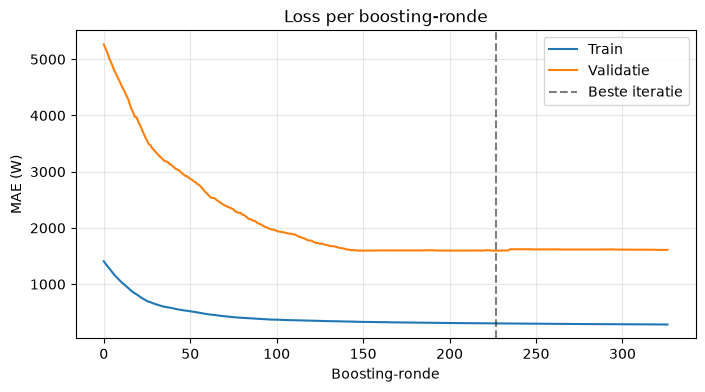

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(evals["train"]["l1"], label="Train")
plt.plot(evals["val"]["l1"], label="Validatie")
plt.axvline(model.best_iteration, color="black", linestyle="--", alpha=0.5, label="Beste iteratie")
plt.xlabel("Boosting-ronde")
plt.ylabel("MAE (W)")
plt.title("Loss per boosting-ronde")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

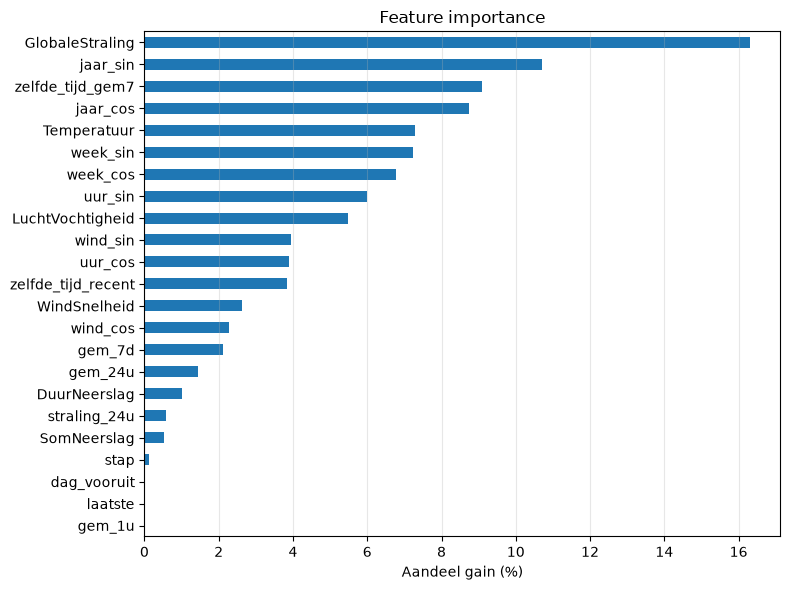

In [10]:
importance = pd.Series(model.feature_importance("gain"), index=FEATURES).sort_values()
plt.figure(figsize=(8, 6))
(importance / importance.sum() * 100).plot.barh()
plt.xlabel("Aandeel gain (%)")
plt.title("Feature importance")
plt.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

### Evaluatie op de testset
---
- Voorspellen in blokken om geheugen te sparen; voorspeltijd wordt apart gemeten.
- Baseline ter vergelijking: *persistence* (zelfde tijdstip van de meest recente bekende dag).

Voorspellen 385 forecasts: 0.4s (0.9 ms per forecast van 864 stappen)

MAE totaal:  4074 W   (persistence: 4788 W)
RMSE totaal: 7226 W
Dag 1: 4091 W   (persistence: 4783 W)
Dag 2: 3993 W   (persistence: 4693 W)
Dag 3: 4139 W   (persistence: 4886 W)


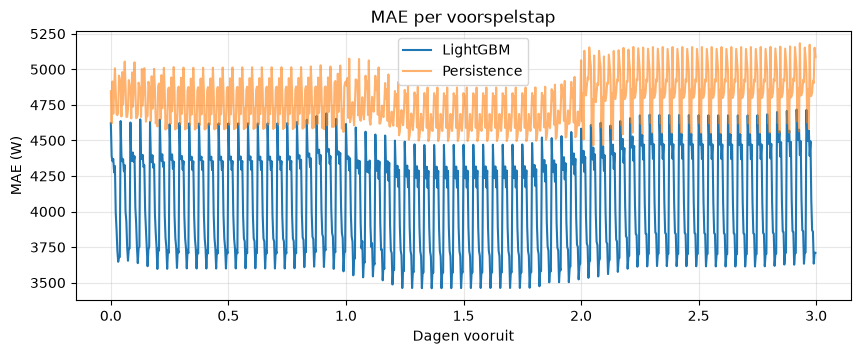

In [11]:
def voorspel(origins, blok=500):
    preds, echt, base = [], [], []
    for i in range(0, len(origins), blok):
        X_blok, y_blok = bouw_rijen(origins[i:i + blok])
        preds.append(model.predict(X_blok, num_iteration=model.best_iteration).reshape(-1, horizon))
        echt.append(y_blok.reshape(-1, horizon))
        base.append(X_blok["zelfde_tijd_recent"].to_numpy().reshape(-1, horizon))
    return np.vstack(preds), np.vstack(echt), np.vstack(base)

t0 = time.perf_counter()
pred_test, echt_test, base_test = voorspel(test_origins)
runtimes["voorspellen test"] = time.perf_counter() - t0
print(f"Voorspellen {len(test_origins)} forecasts: {runtimes['voorspellen test']:.1f}s "
      f"({runtimes['voorspellen test'] / len(test_origins) * 1000:.1f} ms per forecast van {horizon} stappen)")

fouten = np.abs(pred_test - echt_test)
fouten_base = np.abs(base_test - echt_test)
mae_per_stap = fouten.mean(axis=0)

print(f"\nMAE totaal:  {fouten.mean():.0f} W   (persistence: {fouten_base.mean():.0f} W)")
print(f"RMSE totaal: {np.sqrt(((pred_test - echt_test) ** 2).mean()):.0f} W")
for d in range(aantal_dagen_forecast):
    s = slice(d * stap_per_dag, (d + 1) * stap_per_dag)
    print(f"Dag {d+1}: {mae_per_stap[s].mean():.0f} W   (persistence: {fouten_base[:, s].mean():.0f} W)")

plt.figure(figsize=(10, 3.5))
plt.plot(np.arange(horizon) / stap_per_dag, mae_per_stap, label="LightGBM")
plt.plot(np.arange(horizon) / stap_per_dag, fouten_base.mean(axis=0), alpha=0.6, label="Persistence")
plt.xlabel("Dagen vooruit")
plt.ylabel("MAE (W)")
plt.title("MAE per voorspelstap")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

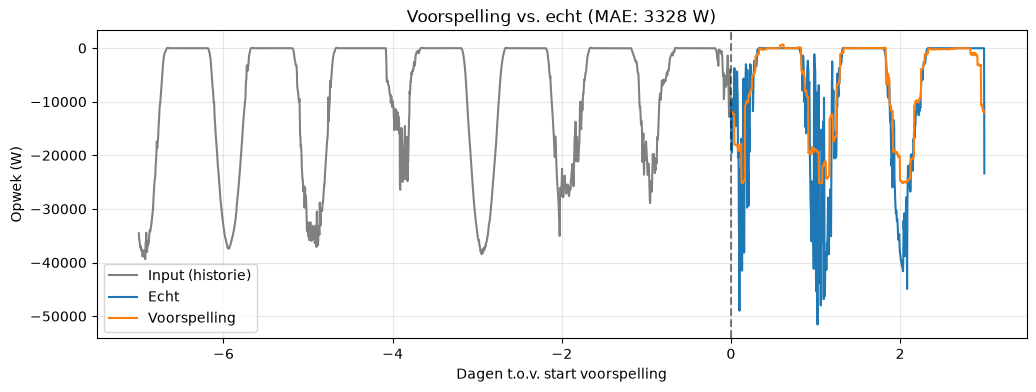

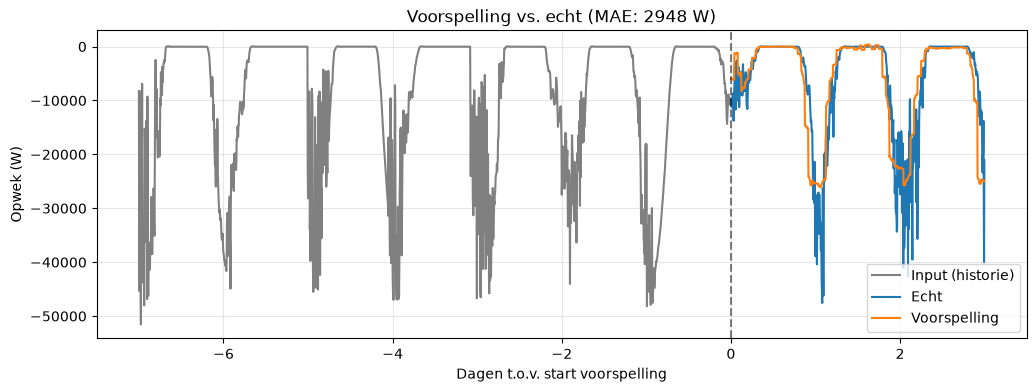

In [12]:
def plot_voorspelling(idx=0, titel="Voorspelling vs. echt"):
    o = test_origins[idx]
    hist = y_arr[o - input_len:o]
    echt, pred = echt_test[idx], pred_test[idx]
    mae = np.abs(pred - echt).mean()

    t_hist = np.arange(-input_len, 0) / stap_per_dag     # x-as in dagen
    t_fc = np.arange(horizon) / stap_per_dag

    plt.figure(figsize=(12, 4))
    plt.plot(t_hist, hist, color="grey", label="Input (historie)")
    plt.plot(t_fc, echt, label="Echt")
    plt.plot(t_fc, pred, label="Voorspelling")
    plt.axvline(0, color="black", linestyle="--", alpha=0.5)
    plt.xlabel("Dagen t.o.v. start voorspelling")
    plt.ylabel("Opwek (W)")
    plt.title(f"{titel} (MAE: {mae:.0f} W)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

plot_voorspelling(idx=0)
plot_voorspelling(idx=len(test_origins) // 2)   # een ander moment

### Rolling validation
---
- Zelfde aanpak als `generation_rolling_validation`: elke dag (stap 288) een nieuwe forecast van 3 dagen, MAE en RMSE in Watt gemiddeld over alle vensters.

In [13]:
def rolling_validatie(begin, eind, step_size=stap_per_dag):
    origins = begin + input_len + np.arange(0, (eind - begin) - input_len - horizon + 1, step_size)
    pred, echt, _ = voorspel(origins)
    maes = np.abs(pred - echt).mean(axis=1)
    rmses = np.sqrt(((pred - echt) ** 2).mean(axis=1))
    return len(origins), maes, rmses

for naam, (begin, eind) in {"validatie": (i_train, i_val), "test": (i_val, n)}.items():
    aantal, maes, rmses = rolling_validatie(begin, eind)
    print(f"{naam:10s} | {aantal} rolling windows | MAE: {maes.mean():.2f} W | RMSE: {rmses.mean():.2f} W")

validatie  | 17 rolling windows | MAE: 1727.06 W | RMSE: 3301.31 W
test       | 17 rolling windows | MAE: 4038.63 W | RMSE: 7106.17 W


### Runtime overzicht
---

In [14]:
runtimes["totaal notebook"] = time.perf_counter() - start_notebook
runtime_df = pd.DataFrame({"seconden": runtimes}).assign(minuten=lambda d: d["seconden"] / 60).round(2)
runtime_df

,seconden,minuten
data inladen,0.13,0.00
features bouwen,0.11,0.00
training,3.20,0.05
voorspellen test,0.35,0.01
totaal notebook,4.64,0.08


### Resultaten opslaan
---
- Zelfde format als de andere modellen, opgeslagen in `models/results/`
- Persistence dag = zelfde tijdstip van de meest recente bekende dag, persistence week = zelfde tijdstip een week eerder

In [15]:
#Projectmap zoeken, werkt vanuit elke submap van models/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "prepared_data").exists())
RESULTS_DIR = ROOT / "models" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def scores(pred, echt):
    fout = pred - echt
    res = {"MAE": np.abs(fout).mean(), "RMSE": np.sqrt((fout ** 2).mean())}
    for d in range(aantal_dagen_forecast):
        s = slice(d * stap_per_dag, (d + 1) * stap_per_dag)
        res[f"MAE dag {d+1}"] = np.abs(fout[:, s]).mean()
    #Rolling validation: elke dag een nieuwe forecast
    dagelijks = slice(None, None, stap_per_dag // stride_test)
    res["rolling MAE"] = np.abs(fout[dagelijks]).mean(axis=1).mean()
    res["rolling RMSE"] = np.sqrt((fout[dagelijks] ** 2).mean(axis=1)).mean()
    return res

h = np.arange(horizon)
t = test_origins[:, None] + h[None, :]
base_dag = y_arr[t - stap_per_dag * (h // stap_per_dag + 1)]
base_week = y_arr[t - input_len]

alle = {"LightGBM": pred_test, "Persistence dag": base_dag, "Persistence week": base_week}
resultaten = pd.DataFrame({naam: scores(pred, echt_test) for naam, pred in alle.items()}).T
resultaten.loc["LightGBM", "trainingstijd (s)"] = runtimes["training"]
resultaten.loc["LightGBM", "voorspeltijd (s)"] = runtimes["voorspellen test"]
resultaten = resultaten.round(1)

#Model opslaan en bestandsgrootte meten
MODEL_DIR = ROOT / "models" / "saved_models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

def grootte_mb(pad):
    pad = Path(pad)
    if pad.is_dir():
        return sum(f.stat().st_size for f in pad.rglob("*") if f.is_file()) / 1e6
    return pad.stat().st_size / 1e6

pad = MODEL_DIR / "11d_lightgbm_carport_gen.txt"
model.save_model(str(pad), num_iteration=model.best_iteration)
resultaten.loc["LightGBM", "modelgrootte (MB)"] = grootte_mb(pad)
resultaten["modelgrootte (MB)"] = resultaten["modelgrootte (MB)"].round(3)

KOLOMMEN = ["notebook", "locatie", "target", "resolutie", "testperiode", "MAE", "RMSE", "MAE dag 1", "MAE dag 2",
            "MAE dag 3", "rolling MAE", "rolling RMSE", "trainingstijd (s)", "voorspeltijd (s)",
            "modelgrootte (MB)"]
resultaten["notebook"] = "11d_LightGBM_carport_gen"
resultaten["locatie"] = "carport"
resultaten["target"] = "generation"
resultaten["resolutie"] = "5 min"
resultaten["testperiode"] = f"{carport_generation['timestamp'].iloc[i_val]:%Y-%m-%d} t/m {carport_generation['timestamp'].iloc[-1]:%Y-%m-%d}"
resultaten = resultaten.reindex(columns=KOLOMMEN)
resultaten.to_csv(RESULTS_DIR / "11d_lightgbm_carport_gen.csv")
resultaten

,notebook,locatie,target,resolutie,testperiode,MAE,RMSE,MAE dag 1,MAE dag 2,MAE dag 3,rolling MAE,rolling RMSE,trainingstijd (s),voorspeltijd (s),modelgrootte (MB)
LightGBM,11d_LightGBM_carport_gen,carport,generation,5 min,2026-03-18 t/m 2026-04-13,4074.4,7225.9,4091.2,3992.9,4138.9,4038.6,7106.2,3.2,0.4,1.349
Persistence dag,11d_LightGBM_carport_gen,carport,generation,5 min,2026-03-18 t/m 2026-04-13,4787.6,9092.5,4783.3,4693.5,4886.1,4756.2,8921.2,NaN,NaN,NaN
Persistence week,11d_LightGBM_carport_gen,carport,generation,5 min,2026-03-18 t/m 2026-04-13,4799.6,9148.3,4757.5,4731.7,4909.5,4791.1,9021.9,NaN,NaN,NaN
